<a href="https://colab.research.google.com/github/Ashok-Harijana/Scholorship-management/blob/main/Mango_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

from google.colab import files

uploaded = files.upload()



Saving train.zip to train.zip


In [3]:

import zipfile
import os

zip_path = "/content/train.zip"
extract_path = "/content/dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset uploaded successfully!")

print(os.listdir(extract_path))


Dataset uploaded successfully!
['train']


In [7]:
dataset_path = "/content/dataset/train"


In [8]:

import os

for folder in ["Ripe", "Rotten", "Unripe"]:

    path = os.path.join(dataset_path, folder)

    images = [
        f for f in os.listdir(path)
        if f.lower().endswith(
            ('.jpg', '.jpeg', '.png', '.bmp')
        )
    ]

    print(folder, ":", len(images), "images")


Ripe : 497 images
Rotten : 1492 images
Unripe : 487 images


In [9]:

!pip install scikit-image opencv-python pandas scikit-learn tensorflow matplotlib seaborn


In [12]:

import os
import cv2
import numpy as np
import pandas as pd

from skimage.feature import hog
from tqdm.notebook import tqdm

dataset_path = "/content/dataset/train"

features = []
labels = []

classes = ["Ripe", "Rotten", "Unripe"]

for class_name in classes:

    folder_path = os.path.join(dataset_path, class_name)

    for image_name in tqdm(os.listdir(folder_path)):

        image_path = os.path.join(folder_path, image_name)

        image = cv2.imread(image_path)

        if image is None:
            continue

        # Resize image
        image = cv2.resize(image, (128, 128))

        # Convert to grayscale
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        # HOG feature extraction
        hog_features = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )

        features.append(hog_features)
        labels.append(class_name)

# Create CSV
df = pd.DataFrame(features)

df["label"] = labels

df.to_csv(
    "/content/fruit_hog_features.csv",
    index=False
)

print("HOG extraction completed!")
print("Total images:", len(df))
print("CSV shape:", df.shape)

df.head()


  0%|          | 0/497 [00:00<?, ?it/s]

  0%|          | 0/1492 [00:00<?, ?it/s]

  0%|          | 0/487 [00:00<?, ?it/s]

HOG extraction completed!
Total images: 2476
CSV shape: (2476, 8101)


,0,1,2,3,4,5,6,7,8,9,...,8091,8092,8093,8094,8095,8096,8097,8098,8099,label
0,0.349896,0.016782,0.022211,0.047707,0.037446,0.000000,0.000000,0.100326,0.349896,0.349896,...,0.004129,0.000000,0.000000,0.000000,0.417695,0.000000,0.000000,0.000000,0.000000,Ripe
1,0.334048,0.000000,0.113470,0.000000,0.267452,0.000000,0.113470,0.000000,0.000000,0.320943,...,0.387730,0.000000,0.195902,0.000000,0.138524,0.000000,0.087067,0.068833,0.000000,Ripe
2,0.214806,0.168520,0.140747,0.139697,0.214806,0.125940,0.102245,0.171049,0.090731,0.214806,...,0.228146,0.118194,0.126948,0.014137,0.228146,0.109399,0.181743,0.228146,0.159274,Ripe
3,0.147615,0.114827,0.102371,0.047096,0.126490,0.072211,0.059996,0.051469,0.011477,0.110579,...,0.302760,0.000000,0.129235,0.082219,0.289379,0.082219,0.301548,0.123027,0.000000,Ripe
4,0.221627,0.063547,0.118378,0.181302,0.216079,0.221627,0.069804,0.124022,0.179962,0.221627,...,0.242813,0.210307,0.242813,0.169581,0.242813,0.000000,0.155640,0.085952,0.072182,Ripe


In [13]:
from google.colab import files

files.download("/content/fruit_hog_features.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
import pandas as pd

df = pd.read_csv("fruit_hog_features.csv")

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nClass distribution:")
print(df["label"].value_counts())

Dataset shape: (2476, 8101)

First 5 rows:


,0,1,2,3,4,5,6,7,8,9,...,8091,8092,8093,8094,8095,8096,8097,8098,8099,label
0,0.349896,0.016782,0.022211,0.047707,0.037446,0.000000,0.000000,0.100326,0.349896,0.349896,...,0.004129,0.000000,0.000000,0.000000,0.417695,0.000000,0.000000,0.000000,0.000000,Ripe
1,0.334048,0.000000,0.113470,0.000000,0.267452,0.000000,0.113470,0.000000,0.000000,0.320943,...,0.387730,0.000000,0.195902,0.000000,0.138524,0.000000,0.087067,0.068833,0.000000,Ripe
2,0.214806,0.168520,0.140747,0.139697,0.214806,0.125940,0.102245,0.171049,0.090731,0.214806,...,0.228146,0.118194,0.126948,0.014137,0.228146,0.109399,0.181743,0.228146,0.159274,Ripe
3,0.147615,0.114827,0.102371,0.047096,0.126490,0.072211,0.059996,0.051469,0.011477,0.110579,...,0.302760,0.000000,0.129235,0.082219,0.289379,0.082219,0.301548,0.123027,0.000000,Ripe
4,0.221627,0.063547,0.118378,0.181302,0.216079,0.221627,0.069804,0.124022,0.179962,0.221627,...,0.242813,0.210307,0.242813,0.169581,0.242813,0.000000,0.155640,0.085952,0.072182,Ripe



Class distribution:
label
Rotten    1492
Ripe       497
Unripe     487
Name: count, dtype: int64


In [16]:
import numpy as np

X = df.drop("label", axis=1).values
y = df["label"].values

print("Feature shape:", X.shape)
print("Label shape:", y.shape)

Feature shape: (2476, 8100)
Label shape: (2476,)


In [17]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y = encoder.fit_transform(y)

print("Class names:", encoder.classes_)

print("Encoded labels:", np.unique(y))

Class names: ['Ripe' 'Rotten' 'Unripe']
Encoded labels: [0 1 2]


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1980, 8100)
Testing data: (496, 8100)


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print("Normalization completed!")

Normalization completed!


In [20]:

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

model = Sequential([

    Input(shape=(X_train.shape[1],)),

    Dense(256, activation="relu"),

    Dropout(0.3),

    Dense(128, activation="relu"),

    Dropout(0.2),

    Dense(64, activation="relu"),

    Dense(3, activation="softmax")

])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     2,073,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,115,203 (8.07 MB)

 Trainable params: 2,115,203 (8.07 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:

history = model.fit(

    X_train,
    y_train,

    epochs=50,

    batch_size=32,

    validation_split=0.2,

    verbose=1

)


Epoch 1/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 116ms/step - accuracy: 0.6869 - loss: 0.9198 - val_accuracy: 0.8157 - val_loss: 0.4785
Epoch 2/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 64ms/step - accuracy: 0.8712 - loss: 0.3858 - val_accuracy: 0.8687 - val_loss: 0.3847
Epoch 3/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 84ms/step - accuracy: 0.9104 - loss: 0.2733 - val_accuracy: 0.8687 - val_loss: 0.3977
Epoch 4/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.9318 - loss: 0.1861 - val_accuracy: 0.8485 - val_loss: 0.4768
Epoch 5/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9388 - loss: 0.1689 - val_accuracy: 0.8510 - val_loss: 0.4369
Epoch 6/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.9583 - loss: 0.1249 - val_accuracy: 0.8687 - val_loss: 0.4688
Epoch 7/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9741 - loss: 0.0670 - val_accuracy: 0.8965 - val_loss: 0.4364
Epoch 8/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.9779 - loss: 0.0620 - val_accuracy: 0.8889 - 

In [22]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Testing Accuracy:", test_accuracy * 100, "%")
print("Testing Loss:", test_loss)

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8810 - loss: 1.0053
Testing Accuracy: 88.10483813285828 %
Testing Loss: 1.0053246021270752


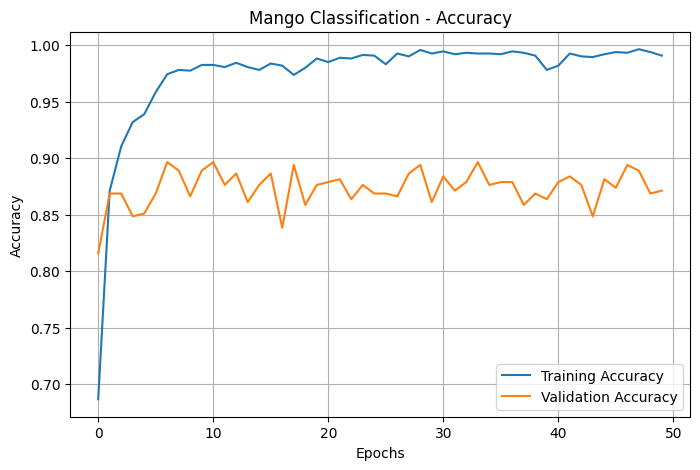

In [23]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Mango Classification - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.grid()
plt.show()


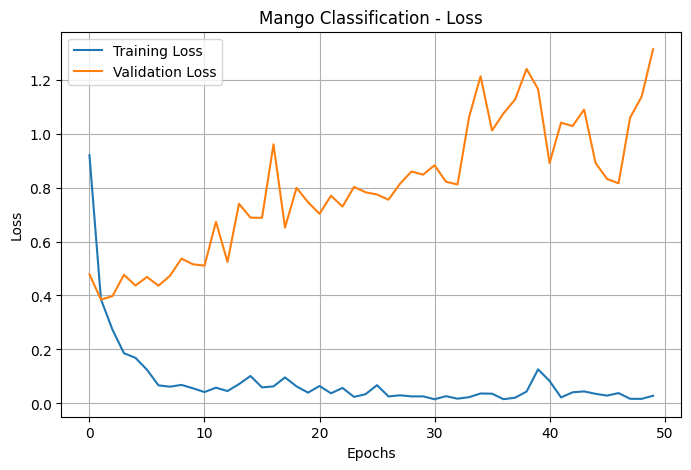

In [24]:

plt.figure(figsize=(8,5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Mango Classification - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.grid()
plt.show()


16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


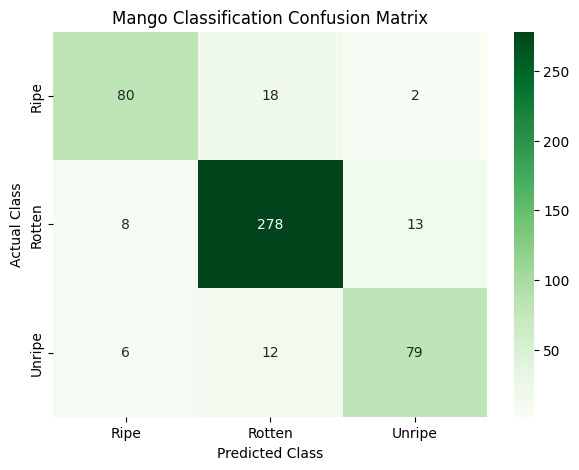

              precision    recall  f1-score   support

        Ripe       0.85      0.80      0.82       100
      Rotten       0.90      0.93      0.92       299
      Unripe       0.84      0.81      0.83        97

    accuracy                           0.88       496
   macro avg       0.86      0.85      0.86       496
weighted avg       0.88      0.88      0.88       496



In [25]:

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Predict test images
y_pred = model.predict(X_test)

# Convert probabilities to class numbers
y_pred_classes = np.argmax(y_pred, axis=1)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Mango Classification Confusion Matrix')

plt.show()

# Classification report
print(classification_report(
    y_test,
    y_pred_classes,
    target_names=encoder.classes_
))


In [26]:

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)


history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights,
    verbose=1
)

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("New Testing Accuracy:", test_accuracy * 100)
print("New Testing Loss:", test_loss)


Class weights: {np.int64(0): np.float64(1.6624685138539044), np.int64(1): np.float64(0.5532271584241408), np.int64(2): np.float64(1.6923076923076923)}
Epoch 1/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.9924 - loss: 0.0258 - val_accuracy: 0.8510 - val_loss: 1.4393
Epoch 2/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.9937 - loss: 0.0215 - val_accuracy: 0.8788 - val_loss: 1.2068
Epoch 3/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.9943 - loss: 0.0358 - val_accuracy: 0.8838 - val_loss: 1.3048
Epoch 4/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.9956 - loss: 0.0389 - val_accuracy: 0.8838 - val_loss: 1.1853
Epoch 5/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.9912 - loss: 0.0572 - val_accuracy: 0.8813 - val_loss: 1.2019
Epoch 6/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.9893 - loss: 0.0627 - val_accuracy: 0.8586 - val_loss: 1.1227
Epoch 7/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.9912 - loss: 0.0546 - 

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
              precision    recall  f1-score   support

        Ripe       0.89      0.84      0.87       100
      Rotten       0.93      0.92      0.93       299
      Unripe       0.83      0.90      0.86        97

    accuracy                           0.90       496
   macro avg       0.88      0.89      0.88       496
weighted avg       0.90      0.90      0.90       496



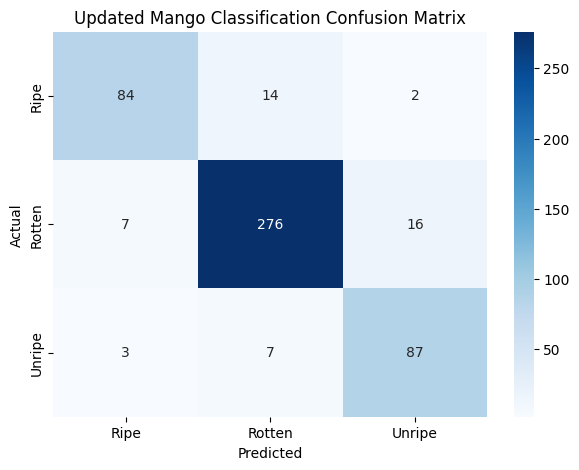

In [27]:

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Predict using updated model
y_pred = model.predict(X_test)

y_pred_classes = np.argmax(y_pred, axis=1)

# Classification report
print(classification_report(
    y_test,
    y_pred_classes,
    target_names=encoder.classes_
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Updated Mango Classification Confusion Matrix")

plt.show()


In [28]:

model.save("/content/mango_classification_model.keras")

import joblib

joblib.dump(scaler, "/content/mango_scaler.pkl")
joblib.dump(encoder, "/content/mango_encoder.pkl")

print("Mango classification model saved successfully!")


Mango classification model saved successfully!


In [29]:
import joblib

# Save TensorFlow model
model.save("/content/mango_model.keras")

# Save scaler
joblib.dump(
    scaler,
    "/content/mango_scaler.pkl"
)

# Save label encoder
joblib.dump(
    encoder,
    "/content/mango_encoder.pkl"
)

print("All files saved successfully!")


All files saved successfully!


In [30]:
from google.colab import files

files.download("/content/mango_model.keras")
files.download("/content/mango_scaler.pkl")
files.download("/content/mango_encoder.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
from google.colab import files

import tensorflow as tf
import joblib


# Load all three files
model = tf.keras.models.load_model("mango_model.keras")

scaler = joblib.load("mango_scaler.pkl")

encoder = joblib.load("mango_encoder.pkl")

print("All three files loaded successfully!")

All three files loaded successfully!


In [49]:
from google.colab import files

print("Upload a new mango image:")
uploaded_image = files.upload()

image_path = next(iter(uploaded_image))

print("Image uploaded successfully:", image_path)

Upload a new mango image:


Saving mango_rott1.jfif to mango_rott1.jfif
Image uploaded successfully: mango_rott1.jfif


In [50]:
import cv2
import numpy as np
from skimage.feature import hog

img = cv2.imread(image_path)

if img is None:
    raise ValueError("Image could not be read.")

img = cv2.resize(img, (128, 128))

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

features = hog(
    gray,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys"
)

features = np.array(features).reshape(1, -1)

features_scaled = scaler.transform(features)

print("Image preprocessing completed!")

Image preprocessing completed!


In [51]:
prediction = model.predict(features_scaled, verbose=0)

predicted_index = np.argmax(prediction)

predicted_class = encoder.inverse_transform(
    [predicted_index]
)[0]

confidence = prediction[0][predicted_index] * 100

print("Mango Classification:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

Mango Classification: Rotten
Confidence: 99.99 %


Web interface for model

In [52]:
!pip install -q gradio

In [53]:

import gradio as gr
import cv2
import numpy as np
from skimage.feature import hog

# Function to classify mango images
def classify_mango(image):

    if image is None:
        return {}, "Please upload a mango image."

    # Convert uploaded RGB image to grayscale
    image = cv2.resize(image, (128, 128))
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # Extract HOG features
    features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

    features = np.array(features).reshape(1, -1)

    # Scale features
    features_scaled = scaler.transform(features)

    # Predict using trained ANN model
    prediction = model.predict(features_scaled, verbose=0)[0]

    # Get class names and probabilities
    class_names = encoder.inverse_transform(
        np.arange(len(prediction))
    )

    results = {
        str(class_names[i]): float(prediction[i])
        for i in range(len(prediction))
    }

    # Find predicted class
    predicted_index = np.argmax(prediction)
    predicted_class = class_names[predicted_index]
    confidence = prediction[predicted_index] * 100

    result_text = (
        f"Predicted Mango Class: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )

    return results, result_text


# Create web application
app = gr.Interface(
    fn=classify_mango,
    inputs=gr.Image(
        type="numpy",
        label="Upload Mango Image"
    ),
    outputs=[
        gr.Label(
            num_top_classes=3,
            label="Classification Results"
        ),
        gr.Textbox(label="Final Prediction")
    ],
    title="🥭 Mango Ripeness Classification",
    description=(
        "Upload a mango image to classify it as "
        "Ripe, Rotten, or Unripe using a trained HOG + ANN model."
    )
)

# Launch web app
app.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3b60c181089b2d712a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
